In [1]:
import sys
import importlib
from importlib.metadata import version

print("Python:", sys.version)
print("Path:", sys.executable)
assert sys.prefix != sys.base_prefix, "Select project kernel"

packages = {
    "torch": "torch", "torchvision": "torchvision",
    "transformers": "transformers",
    "sentence_transformers": "sentence-transformers",
    "PIL": "Pillow", "cv2": "opencv-python",
    "matplotlib": "matplotlib", "numpy": "numpy",
    "pandas": "pandas", "sklearn": "scikit-learn",
    "jiwer": "jiwer", "openpyxl": "openpyxl",
    "requests": "requests", "dotenv": "python-dotenv",
}

for module, package in packages.items():
    importlib.import_module(module)
    print("OK:", package, version(package))

Python: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
Path: c:\Users\KINGDOM\mentrix-ai\.venv\Scripts\python.exe
OK: torch 2.9.1+cu126
OK: torchvision 0.24.1+cu126


c:\Users\KINGDOM\mentrix-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK: transformers 5.20.2


W1021 14:50:04.482000 18740 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


OK: sentence-transformers 6.1.0
OK: Pillow 12.3.0
OK: opencv-python 5.0.0.93
OK: matplotlib 3.11.2
OK: numpy 2.5.2
OK: pandas 3.0.6
OK: scikit-learn 1.9.1
OK: jiwer 4.0.0
OK: openpyxl 3.1.5
OK: requests 2.34.2
OK: python-dotenv 1.2.4


In [2]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
a = torch.ones((2, 2), device=device)

print("Device:", device)
print((a @ a).cpu())

if device == "cuda":
    info = torch.cuda.get_device_properties(0)
    print("GPU:", info.name)
    print("VRAM GB:", round(info.total_memory / 1024**3, 2))

Device: cuda
tensor([[2., 2.],
        [2., 2.]])
GPU: Quadro T2000 with Max-Q Design
VRAM GB: 4.0


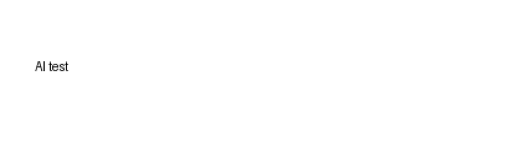

In [3]:
from pathlib import Path
from PIL import Image, ImageDraw
import cv2
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

folder = root / "results"
folder.mkdir(exist_ok=True)

image = Image.new("RGB", (400, 120), "white")
ImageDraw.Draw(image).text((20, 40), "AI test", fill="black")

path = folder / "test.png"
image.save(path)

loaded = cv2.imread(str(path))
assert loaded is not None

gray = cv2.cvtColor(loaded, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

In [4]:
import pandas as pd

data = pd.DataFrame({
    "sample_id": [1, 2],
    "score": [3, 4]
})

path = folder / "test.xlsx"
data.to_excel(path, index=False)

loaded = pd.read_excel(path)
pd.testing.assert_frame_equal(data, loaded)

print("Excel: OK")

Excel: OK


In [5]:
from jiwer import cer, wer

reference = "The cell contains a nucleus"
prediction = "The cell contains nucleus"

print("CER:", cer(reference, prediction))
print("WER:", wer(reference, prediction))

assert wer(reference, reference) == 0

CER: 0.07407407407407407
WER: 0.2


In [6]:
import sympy as sp

x = sp.symbols("x")
a = (x + 1)**2
b = x**2 + 2*x + 1

print(sp.simplify(a - b) == 0)

True


In [7]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cpu"
)

texts = [
    "The student attended.",
    "The student was present."
]

embeddings = model.encode(texts)

print("Embeddings shape:", embeddings.shape)
assert embeddings.shape[0] == 2

c:\Users\KINGDOM\mentrix-ai\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\KINGDOM\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\KINGDOM\mentrix-ai\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: User

Embeddings shape: (2, 384)
